In [5]:
# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

import copy
import time

# ==========================================
# STEP 2: SELECT COMPUTING DEVICE
# ==========================================

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Using device:", device)

# ==========================================
# STEP 3: LOAD PREPROCESSED DATA
# ==========================================

data = np.load("../data/processed/preprocessed_data.npz")

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

print("\nDataset shapes:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Using device: mps

Dataset shapes:
Training: (14241, 30, 18) (14241,)
Validation: (3490, 30, 18) (3490,)
Testing: (100, 30, 18) (100,)


In [2]:
# ==========================================
# STEP 4: CREATE PYTORCH DATALOADERS
# ==========================================

BATCH_SIZE = 128

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 112
Validation batches: 28


In [3]:
# ==========================================
# STEP 5: BUILD BiLSTM MODEL
# ==========================================

class BiLSTMModel(nn.Module):

    def __init__(self, input_size=18, hidden_size=64, num_layers=2):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


# Initialize model
bilstm_model = BiLSTMModel().to(device)

print(bilstm_model)

BiLSTMModel(
  (lstm): LSTM(18, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [4]:
# ==========================================
# STEP 6: TRAIN BiLSTM MODEL
# ==========================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=0.001
)

EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
patience_counter = 0
best_model_weights = None

start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    bilstm_model.train()
    train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = bilstm_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    bilstm_model.eval()
    val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = bilstm_model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    # Early stopping
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(
            bilstm_model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore best weights
bilstm_model.load_state_dict(best_model_weights)

training_time = time.time() - start_time

print("\nBest validation loss:", best_val_loss)
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/30] Train Loss: 5552.3667 Val Loss: 2161.3524
Epoch [2/30] Train Loss: 1204.7580 Val Loss: 436.1800
Epoch [3/30] Train Loss: 550.7738 Val Loss: 316.9165
Epoch [4/30] Train Loss: 516.7510 Val Loss: 297.4710
Epoch [5/30] Train Loss: 486.2618 Val Loss: 284.0969
Epoch [6/30] Train Loss: 468.4751 Val Loss: 259.5141
Epoch [7/30] Train Loss: 437.2810 Val Loss: 226.8518
Epoch [8/30] Train Loss: 381.8578 Val Loss: 244.6049
Epoch [9/30] Train Loss: 329.3695 Val Loss: 190.2439
Epoch [10/30] Train Loss: 304.3205 Val Loss: 191.5960
Epoch [11/30] Train Loss: 297.7070 Val Loss: 161.3054
Epoch [12/30] Train Loss: 279.8580 Val Loss: 165.0823
Epoch [13/30] Train Loss: 266.8320 Val Loss: 174.6169
Epoch [14/30] Train Loss: 248.0380 Val Loss: 168.6372
Epoch [15/30] Train Loss: 243.2584 Val Loss: 183.0365
Epoch [16/30] Train Loss: 235.5147 Val Loss: 204.8034
Early stopping triggered.

Best validation loss: 161.3053582736424
Training time: 56.69 seconds


In [5]:
# STEP 7: VALIDATION EVALUATION

from sklearn.metrics import mean_absolute_error, mean_squared_error

bilstm_model.eval()

val_predictions = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        predictions = bilstm_model(X_batch)
        val_predictions.extend(predictions.cpu().numpy())

val_predictions = np.array(val_predictions)

val_mae = mean_absolute_error(y_val, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val, val_predictions))

print("BiLSTM Validation Results")
print("-------------------------")
print(f"MAE:  {val_mae:.2f}")
print(f"RMSE: {val_rmse:.2f}")

BiLSTM Validation Results
-------------------------
MAE:  9.09
RMSE: 12.85


In [6]:
# STEP 8: SAVE BiLSTM MODEL

import os

os.makedirs("../artifacts/models", exist_ok=True)

torch.save(
    bilstm_model.state_dict(),
    "../artifacts/models/bilstm_model.pth"
)

print("BiLSTM model saved successfully!")

BiLSTM model saved successfully!


In [7]:
# STEP 9: TCN MODEL ARCHITECTURE

class TCNModel(nn.Module):

    def __init__(self, input_size=18, channels=64):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(input_size, channels, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(channels, channels, kernel_size=3,
                      padding=2, dilation=2),
            nn.ReLU(),

            nn.Conv1d(channels, channels, kernel_size=3,
                      padding=4, dilation=4),
            nn.ReLU()
        )

        self.fc = nn.Sequential(
            nn.Linear(channels, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        # Change shape: (batch, time, features)
        # to (batch, features, time)
        x = x.transpose(1, 2)

        output = self.network(x)

        # Take the final time-step representation
        last_output = output[:, :, -1]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


tcn_model = TCNModel().to(device)

print(tcn_model)

TCNModel(
  (network): Sequential(
    (0): Conv1d(18, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
    (3): ReLU()
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(4,))
    (5): ReLU()
  )
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [8]:
# STEP 10: TRAIN TCN MODEL

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    tcn_model.parameters(),
    lr=0.001
)

EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
patience_counter = 0
best_model_weights = None

start_time = time.time()

for epoch in range(EPOCHS):

    tcn_model.train()
    train_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = tcn_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    tcn_model.eval()
    val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = tcn_model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(tcn_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

tcn_model.load_state_dict(best_model_weights)

training_time = time.time() - start_time

print("\nBest TCN validation loss:", best_val_loss)
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/30] Train Loss: 3706.7003 Val Loss: 614.7055
Epoch [2/30] Train Loss: 720.1333 Val Loss: 366.7803
Epoch [3/30] Train Loss: 570.5429 Val Loss: 343.6762
Epoch [4/30] Train Loss: 544.5617 Val Loss: 339.0783
Epoch [5/30] Train Loss: 535.4321 Val Loss: 328.7806
Epoch [6/30] Train Loss: 517.3615 Val Loss: 332.2513
Epoch [7/30] Train Loss: 510.3247 Val Loss: 315.7167
Epoch [8/30] Train Loss: 502.0112 Val Loss: 316.4943
Epoch [9/30] Train Loss: 490.5874 Val Loss: 308.7737
Epoch [10/30] Train Loss: 461.9059 Val Loss: 293.5895
Epoch [11/30] Train Loss: 461.4630 Val Loss: 299.0425
Epoch [12/30] Train Loss: 444.1623 Val Loss: 303.0876
Epoch [13/30] Train Loss: 441.7868 Val Loss: 293.7591
Epoch [14/30] Train Loss: 434.5971 Val Loss: 293.2027
Epoch [15/30] Train Loss: 442.0689 Val Loss: 312.7257
Epoch [16/30] Train Loss: 426.3267 Val Loss: 294.4598
Epoch [17/30] Train Loss: 423.4768 Val Loss: 309.2874
Epoch [18/30] Train Loss: 423.3177 Val Loss: 303.5624
Epoch [19/30] Train Loss: 416.0146 V

In [9]:
# STEP 11: TCN VALIDATION EVALUATION

tcn_model.eval()

tcn_predictions = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        predictions = tcn_model(X_batch)

        tcn_predictions.extend(predictions.cpu().numpy())

tcn_predictions = np.array(tcn_predictions)

tcn_mae = mean_absolute_error(y_val, tcn_predictions)
tcn_rmse = np.sqrt(mean_squared_error(y_val, tcn_predictions))

print("TCN Validation Results")
print("----------------------")
print(f"MAE:  {tcn_mae:.2f}")
print(f"RMSE: {tcn_rmse:.2f}")

TCN Validation Results
----------------------
MAE:  12.92
RMSE: 17.34


In [10]:
# STEP 12: SAVE TCN MODEL

torch.save(
    tcn_model.state_dict(),
    "../artifacts/models/tcn_model.pth"
)

print("TCN model saved successfully!")

TCN model saved successfully!


In [11]:
# STEP 13: TRANSFORMER MODEL ARCHITECTURE

class TransformerModel(nn.Module):

    def __init__(
        self,
        input_size=18,
        d_model=64,
        num_heads=4,
        num_layers=2
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_size, d_model)

        self.positional_encoding = nn.Parameter(
            torch.zeros(1, 30, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = x + self.positional_encoding

        output = self.transformer(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


transformer_model = TransformerModel().to(device)

print(transformer_model)

TransformerModel(
  (input_projection): Linear(in_features=18, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, b

In [12]:
# STEP 14: TRAIN TRANSFORMER MODEL

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=0.001
)

EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
patience_counter = 0
best_model_weights = None

start_time = time.time()

for epoch in range(EPOCHS):

    transformer_model.train()
    train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = transformer_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    transformer_model.eval()
    val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = transformer_model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(
            transformer_model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

transformer_model.load_state_dict(best_model_weights)

training_time = time.time() - start_time

print("\nBest Transformer validation loss:", best_val_loss)
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/30] Train Loss: 6538.9184 Val Loss: 3481.0355
Epoch [2/30] Train Loss: 1519.1537 Val Loss: 370.9992
Epoch [3/30] Train Loss: 476.6962 Val Loss: 192.0168
Epoch [4/30] Train Loss: 335.7525 Val Loss: 153.0065
Epoch [5/30] Train Loss: 309.8012 Val Loss: 181.3501
Epoch [6/30] Train Loss: 282.5845 Val Loss: 180.1145
Epoch [7/30] Train Loss: 266.3516 Val Loss: 167.8760
Epoch [8/30] Train Loss: 257.3750 Val Loss: 174.3347
Epoch [9/30] Train Loss: 245.7011 Val Loss: 186.0836
Early stopping triggered.

Best Transformer validation loss: 153.0065403665815
Training time: 29.33 seconds


In [13]:
# STEP 15: TRANSFORMER VALIDATION EVALUATION

transformer_model.eval()

transformer_predictions = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        X_batch = X_batch.to(device)

        predictions = transformer_model(X_batch)

        transformer_predictions.extend(
            predictions.cpu().numpy()
        )

transformer_predictions = np.array(transformer_predictions)

transformer_mae = mean_absolute_error(
    y_val, transformer_predictions
)

transformer_rmse = np.sqrt(
    mean_squared_error(y_val, transformer_predictions)
)

print("Transformer Validation Results")
print("------------------------------")
print(f"MAE:  {transformer_mae:.2f}")
print(f"RMSE: {transformer_rmse:.2f}")

Transformer Validation Results
------------------------------
MAE:  9.21
RMSE: 12.50


In [14]:
# STEP 16: SAVE TRANSFORMER MODEL

torch.save(
    transformer_model.state_dict(),
    "../artifacts/models/transformer_model.pth"
)

print("Transformer model saved successfully!")

Transformer model saved successfully!


In [16]:
# STEP 17: MODEL COMPARISON

results = pd.DataFrame({
    "Model": ["BiLSTM", "TCN", "Transformer"],
    "MAE": [val_mae, tcn_mae, transformer_mae],
    "RMSE": [val_rmse, tcn_rmse, transformer_rmse],
    "Training_Time": [56.69, 53.97, 29.33]
})

results = results.sort_values("RMSE")

print(results.to_string(index=False))

      Model       MAE      RMSE  Training_Time
Transformer  9.209670 12.500735          29.33
     BiLSTM  9.088737 12.852862          56.69
        TCN 12.923382 17.343228          53.97


In [17]:
# STEP 18: SAVE MODEL COMPARISON

os.makedirs("../artifacts/metrics", exist_ok=True)

results.to_csv(
    "../artifacts/metrics/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [18]:
# STEP 19: PREPARE TEST DATA

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
).to(device)

print("Test input shape:", X_test_tensor.shape)
print("Test target shape:", y_test_tensor.shape)

Test input shape: torch.Size([100, 30, 18])
Test target shape: torch.Size([100])


In [19]:
# STEP 20: GENERATE TEST PREDICTIONS

bilstm_model.eval()
tcn_model.eval()
transformer_model.eval()

with torch.no_grad():

    bilstm_test_predictions = bilstm_model(
        X_test_tensor
    ).cpu().numpy()

    tcn_test_predictions = tcn_model(
        X_test_tensor
    ).cpu().numpy()

    transformer_test_predictions = transformer_model(
        X_test_tensor
    ).cpu().numpy()


# Keep predictions within the valid RUL range
bilstm_test_predictions = np.clip(
    bilstm_test_predictions, 0, 125
)

tcn_test_predictions = np.clip(
    tcn_test_predictions, 0, 125
)

transformer_test_predictions = np.clip(
    transformer_test_predictions, 0, 125
)


print("Test predictions generated successfully!")
print("BiLSTM:", bilstm_test_predictions.shape)
print("TCN:", tcn_test_predictions.shape)
print("Transformer:", transformer_test_predictions.shape)

Test predictions generated successfully!
BiLSTM: (100,)
TCN: (100,)
Transformer: (100,)


In [20]:
# STEP 21: FINAL TEST EVALUATION

bilstm_test_mae = mean_absolute_error(
    y_test, bilstm_test_predictions
)
bilstm_test_rmse = np.sqrt(
    mean_squared_error(y_test, bilstm_test_predictions)
)

tcn_test_mae = mean_absolute_error(
    y_test, tcn_test_predictions
)
tcn_test_rmse = np.sqrt(
    mean_squared_error(y_test, tcn_test_predictions)
)

transformer_test_mae = mean_absolute_error(
    y_test, transformer_test_predictions
)
transformer_test_rmse = np.sqrt(
    mean_squared_error(y_test, transformer_test_predictions)
)

test_results = pd.DataFrame({
    "Model": ["BiLSTM", "TCN", "Transformer"],
    "MAE": [
        bilstm_test_mae,
        tcn_test_mae,
        transformer_test_mae
    ],
    "RMSE": [
        bilstm_test_rmse,
        tcn_test_rmse,
        transformer_test_rmse
    ]
})

test_results = test_results.sort_values("RMSE")

print("FINAL TEST RESULTS")
print("------------------")
print(test_results.to_string(index=False))

FINAL TEST RESULTS
------------------
      Model       MAE      RMSE
Transformer  9.745177 13.680450
     BiLSTM 11.384054 15.252852
        TCN 12.072762 17.175783


In [22]:
# STEP 22: VERIFY ORIGINAL TEST RUL

original_test_rul = pd.read_csv(
    "../data/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Original maximum test RUL:",
      original_test_rul["RUL"].max())

print("Number of values above 125:",
      (original_test_rul["RUL"] > 125).sum())

Original maximum test RUL: 145
Number of values above 125: 11


In [23]:
# STEP 23: CORRECTED FINAL TEST EVALUATION

# Load original, uncapped test RUL labels
y_test_original = original_test_rul["RUL"].values

# Calculate corrected metrics
corrected_results = pd.DataFrame({
    "Model": ["BiLSTM", "TCN", "Transformer"],
    "MAE": [
        mean_absolute_error(y_test_original, bilstm_test_predictions),
        mean_absolute_error(y_test_original, tcn_test_predictions),
        mean_absolute_error(y_test_original, transformer_test_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_original, bilstm_test_predictions)),
        np.sqrt(mean_squared_error(y_test_original, tcn_test_predictions)),
        np.sqrt(mean_squared_error(y_test_original, transformer_test_predictions))
    ]
})

corrected_results = corrected_results.sort_values("RMSE")

print("CORRECTED FINAL TEST RESULTS")
print("----------------------------")
print(corrected_results.to_string(index=False))

CORRECTED FINAL TEST RESULTS
----------------------------
      Model       MAE      RMSE
Transformer 10.815176 15.034663
     BiLSTM 12.454054 16.529732
        TCN 13.142761 18.341872


In [1]:
# STEP 24: IMPORT OPTUNA

import optuna

print("Optuna version:", optuna.__version__)

Optuna version: 5.1.0


/Users/shama/Documents/Predictive_Maintenance_RUL/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from torch.utils.data import TensorDataset, DataLoader
import torch

In [6]:
# STEP 25: PREPARE DATA FOR OPTUNA

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 14241
Validation samples: 3490


In [7]:
# STEP 26: TRANSFORMER MODEL FOR OPTUNA

class TunableTransformer(nn.Module):

    def __init__(self, d_model, num_heads, num_layers, dropout):
        super().__init__()

        self.input_projection = nn.Linear(18, d_model)

        self.positional_encoding = nn.Parameter(
            torch.zeros(1, 30, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = x + self.positional_encoding

        output = self.transformer(x)
        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [8]:
# STEP 27: CREATE DATALOADERS

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 112
Validation batches: 28


In [9]:
# STEP 28: OPTUNA OBJECTIVE FUNCTION

def objective(trial):

    # Hyperparameters to experiment with
    d_model = trial.suggest_categorical(
        "d_model", [32, 64, 128]
    )

    num_heads = trial.suggest_categorical(
        "num_heads", [2, 4, 8]
    )

    num_layers = trial.suggest_int(
        "num_layers", 1, 3
    )

    dropout = trial.suggest_float(
        "dropout", 0.1, 0.4
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 1e-4, 1e-2, log=True
    )

    # d_model must be divisible by num_heads
    if d_model % num_heads != 0:
        raise optuna.TrialPruned()

    model = TunableTransformer(
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers,
        dropout=dropout
    ).to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Train for a limited number of epochs per trial
    for epoch in range(10):

        model.train()

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            loss.backward()

            optimizer.step()

        # Validation
        model.eval()
        val_losses = []

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)

                val_loss = criterion(predictions, y_batch)

                val_losses.append(val_loss.item())

        average_val_loss = np.mean(val_losses)

        trial.report(average_val_loss, epoch)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return average_val_loss

In [10]:
# STEP 29: RUN OPTUNA

study = optuna.create_study(
    direction="minimize",
    study_name="transformer_rul_optimization"
)

study.optimize(
    objective,
    n_trials=10
)

print("\nBest Trial:")
print("Best Validation MSE:", study.best_value)
print("Best Hyperparameters:", study.best_params)

[I 2026-11-21 18:47:13,287] A new study created in memory with name: transformer_rul_optimization
[I 2026-11-21 18:47:43,776] Trial 0 finished with value: 176.85904502868652 and parameters: {'d_model': 32, 'num_heads': 8, 'num_layers': 2, 'dropout': 0.12442543015572782, 'learning_rate': 0.00036161541447917676}. Best is trial 0 with value: 176.85904502868652.
[I 2026-11-21 18:48:07,640] Trial 1 finished with value: 297.3001855441502 and parameters: {'d_model': 64, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.18814731013185346, 'learning_rate': 0.0035345371052161885}. Best is trial 0 with value: 176.85904502868652.
[I 2026-11-21 18:49:18,284] Trial 2 finished with value: 305.55613081795826 and parameters: {'d_model': 128, 'num_heads': 8, 'num_layers': 3, 'dropout': 0.28349620529790664, 'learning_rate': 0.002540269723723516}. Best is trial 0 with value: 176.85904502868652.
[I 2026-11-21 18:49:29,785] Trial 3 finished with value: 172.26320729936873 and parameters: {'d_model': 32, 'num_hea


Best Trial:
Best Validation MSE: 172.26320729936873
Best Hyperparameters: {'d_model': 32, 'num_heads': 2, 'num_layers': 1, 'dropout': 0.2605961351078744, 'learning_rate': 0.0019467396964836293}


In [11]:
# STEP 31: TRAIN BEST OPTUNA MODEL

best_params = study.best_params

tuned_model = TunableTransformer(
    d_model=best_params["d_model"],
    num_heads=best_params["num_heads"],
    num_layers=best_params["num_layers"],
    dropout=best_params["dropout"]
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    tuned_model.parameters(),
    lr=best_params["learning_rate"]
)

best_val_loss = float("inf")
patience = 5
counter = 0
best_weights = None

for epoch in range(30):

    tuned_model.train()
    train_losses = []

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = tuned_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    tuned_model.eval()
    val_losses = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = tuned_model(X_batch)
            val_loss = criterion(predictions, y_batch)

            val_losses.append(val_loss.item())

    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)

    print(
        f"Epoch [{epoch+1}/30] "
        f"Train Loss: {avg_train_loss:.2f} "
        f"Val Loss: {avg_val_loss:.2f}"
    )

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss
        best_weights = copy.deepcopy(tuned_model.state_dict())
        counter = 0

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

tuned_model.load_state_dict(best_weights)

print("\nBest tuned validation MSE:", best_val_loss)

Epoch [1/30] Train Loss: 5004.43 Val Loss: 627.58
Epoch [2/30] Train Loss: 521.29 Val Loss: 226.45
Epoch [3/30] Train Loss: 401.65 Val Loss: 168.07
Epoch [4/30] Train Loss: 364.18 Val Loss: 156.77
Epoch [5/30] Train Loss: 355.01 Val Loss: 150.47
Epoch [6/30] Train Loss: 343.12 Val Loss: 153.49
Epoch [7/30] Train Loss: 333.97 Val Loss: 170.40
Epoch [8/30] Train Loss: 328.18 Val Loss: 161.02
Epoch [9/30] Train Loss: 323.16 Val Loss: 148.85
Epoch [10/30] Train Loss: 324.65 Val Loss: 153.11
Epoch [11/30] Train Loss: 320.82 Val Loss: 160.67
Epoch [12/30] Train Loss: 326.25 Val Loss: 150.29
Epoch [13/30] Train Loss: 321.10 Val Loss: 155.32
Epoch [14/30] Train Loss: 319.22 Val Loss: 151.76
Early stopping triggered!

Best tuned validation MSE: 148.85010276521956


In [16]:
# RECOVER ORIGINAL TRANSFORMER

import torch
import torch.nn as nn

# Recreate original architecture
class TransformerModel(nn.Module):

    def __init__(self, input_size=18, d_model=64,
                 num_heads=4, num_layers=2):
        super().__init__()

        self.input_projection = nn.Linear(input_size, d_model)
        self.positional_encoding = nn.Parameter(
            torch.zeros(1, 30, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = x + self.positional_encoding
        output = self.transformer(x)
        last_output = output[:, -1, :]
        return self.fc(last_output).squeeze(1)


# Restore saved weights
transformer_model = TransformerModel().to(device)

transformer_model.load_state_dict(
    torch.load(
        "../artifacts/models/transformer_model.pth",
        map_location=device,
        weights_only=True
    )
)

transformer_model.eval()

print("Original Transformer restored successfully!")
print("Model available:", "transformer_model" in globals())

Original Transformer restored successfully!
Model available: True


In [17]:
# STEP 32: COMPARE ORIGINAL AND TUNED TRANSFORMER

from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_validation_model(model, X, y):

    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X, dtype=torch.float32
        ).to(device)

        predictions = model(X_tensor).cpu().numpy()

    predictions = np.clip(predictions, 0, 125)

    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))

    return mae, rmse


original_mae, original_rmse = evaluate_validation_model(
    transformer_model, X_val, y_val
)

tuned_mae, tuned_rmse = evaluate_validation_model(
    tuned_model, X_val, y_val
)

validation_comparison = pd.DataFrame({
    "Model": ["Original Transformer", "Optuna Tuned Transformer"],
    "MAE": [original_mae, tuned_mae],
    "RMSE": [original_rmse, tuned_rmse]
})

print(validation_comparison.round(3))

                      Model    MAE    RMSE
0      Original Transformer  9.210  12.501
1  Optuna Tuned Transformer  8.773  12.347


In [18]:
# STEP 34: SAVE OPTUNA-TUNED MODEL

import os

os.makedirs("../artifacts/models", exist_ok=True)

torch.save(
    tuned_model.state_dict(),
    "../artifacts/models/tuned_transformer_model.pth"
)

print("Tuned Transformer saved successfully!")

Tuned Transformer saved successfully!


In [19]:
# STEP 35: FINAL TEST EVALUATION

tuned_test_predictions = evaluate_validation_model(
    tuned_model, X_test, y_test
)

# Get predictions separately for final reporting
tuned_model.eval()

with torch.no_grad():
    X_test_tensor = torch.tensor(
        X_test, dtype=torch.float32
    ).to(device)

    tuned_test_predictions = tuned_model(
        X_test_tensor
    ).cpu().numpy()

tuned_test_predictions = np.clip(
    tuned_test_predictions, 0, 125
)

# Load original, uncapped test RUL labels
original_test_rul = pd.read_csv(
    "../data/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

y_test_original = original_test_rul["RUL"].values

# Calculate final metrics
tuned_test_mae = mean_absolute_error(
    y_test_original, tuned_test_predictions
)

tuned_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_original, tuned_test_predictions
    )
)

print("OPTUNA-TUNED TRANSFORMER - FINAL TEST RESULTS")
print("----------------------------------------------")
print("MAE:", round(tuned_test_mae, 4))
print("RMSE:", round(tuned_test_rmse, 4))

OPTUNA-TUNED TRANSFORMER - FINAL TEST RESULTS
----------------------------------------------
MAE: 10.2965
RMSE: 14.0759


In [20]:
# STEP 37: SAVE FINAL TEST RESULTS

final_results = pd.DataFrame({
    "Model": [
        "Original Transformer",
        "Optuna Tuned Transformer"
    ],
    "MAE": [
        10.815176,
        tuned_test_mae
    ],
    "RMSE": [
        15.034663,
        tuned_test_rmse
    ]
})

final_results.to_csv(
    "../artifacts/metrics/final_test_results.csv",
    index=False
)

print(final_results.round(4))

print("\nFinal test results saved successfully!")

                      Model      MAE     RMSE
0      Original Transformer  10.8152  15.0347
1  Optuna Tuned Transformer  10.2965  14.0759

Final test results saved successfully!


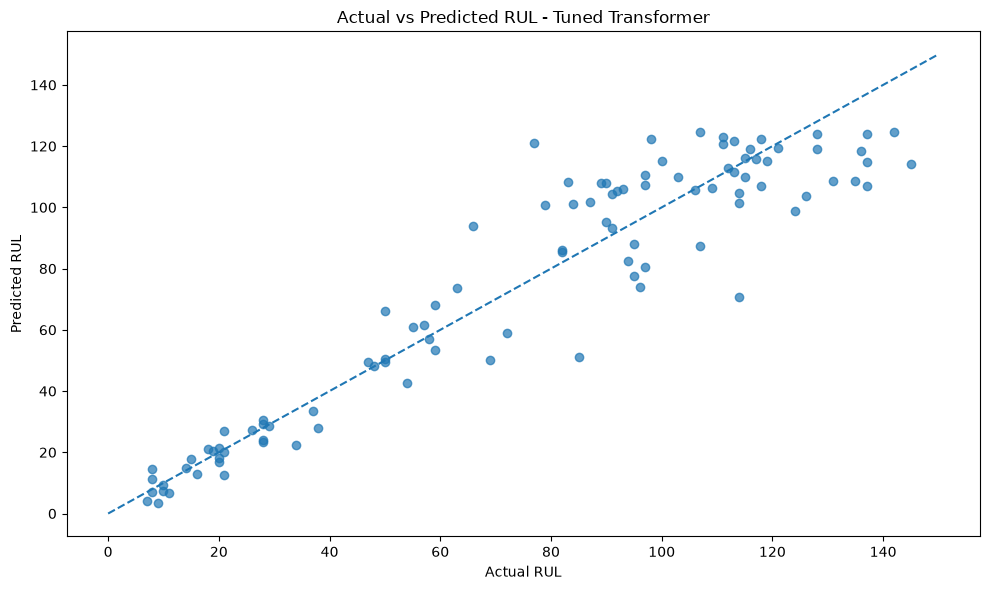

In [21]:
# STEP 38: ACTUAL VS PREDICTED RUL

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test_original,
    tuned_test_predictions,
    alpha=0.7
)

plt.plot(
    [0, 150],
    [0, 150],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Tuned Transformer")

plt.tight_layout()

plt.savefig(
    "../artifacts/plots/actual_vs_predicted_rul.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# STEP 39: NASA SCORING FUNCTION

def nasa_score(actual, predicted):

    errors = predicted - actual

    scores = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )

    return np.sum(scores)


tuned_nasa_score = nasa_score(
    y_test_original,
    tuned_test_predictions
)

print("NASA Score:", round(tuned_nasa_score, 2))

NASA Score: 314.99


In [23]:
# STEP 40: SAVE COMPLETE FINAL EVALUATION

final_evaluation = pd.DataFrame({
    "Model": ["Optuna Tuned Transformer"],
    "MAE": [tuned_test_mae],
    "RMSE": [tuned_test_rmse],
    "NASA_Score": [tuned_nasa_score]
})

final_evaluation.to_csv(
    "../artifacts/metrics/final_model_evaluation.csv",
    index=False
)

print(final_evaluation.round(4))

print("\nFinal evaluation saved successfully!")

                      Model      MAE     RMSE  NASA_Score
0  Optuna Tuned Transformer  10.2965  14.0759    314.9943

Final evaluation saved successfully!


In [24]:
# STEP 42: VERIFY PROJECT ARTIFACTS

import os

files_to_check = [
    "../artifacts/models/tuned_transformer_model.pth",
    "../artifacts/metrics/final_test_results.csv",
    "../artifacts/metrics/final_model_evaluation.csv",
    "../artifacts/metrics/best_hyperparameters.json",
    "../artifacts/plots/actual_vs_predicted_rul.png"
]

for file_path in files_to_check:

    status = "FOUND" if os.path.exists(file_path) else "MISSING"

    print(f"{status}: {file_path}")

FOUND: ../artifacts/models/tuned_transformer_model.pth
FOUND: ../artifacts/metrics/final_test_results.csv
FOUND: ../artifacts/metrics/final_model_evaluation.csv
MISSING: ../artifacts/metrics/best_hyperparameters.json
FOUND: ../artifacts/plots/actual_vs_predicted_rul.png


In [25]:
# STEP 43: SAVE BEST HYPERPARAMETERS

import os
import json

os.makedirs("../artifacts/metrics", exist_ok=True)

best_params = study.best_params

with open(
    "../artifacts/metrics/best_hyperparameters.json",
    "w"
) as file:
    json.dump(best_params, file, indent=4)

print("Best hyperparameters:")
print(json.dumps(best_params, indent=4))

print("\nHyperparameters saved successfully!")

Best hyperparameters:
{
    "d_model": 32,
    "num_heads": 2,
    "num_layers": 1,
    "dropout": 0.2605961351078744,
    "learning_rate": 0.0019467396964836293
}

Hyperparameters saved successfully!
